In [1]:
# Spark session + the constants used throughout (target pollutants, low-cost sensor markers, outlier caps, lockdown dates). log_rule() just prints and records before/after row counts for each cleaning step.
 
import os
from datetime import datetime, timezone

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, IntegerType, StringType

os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
spark = SparkSession.builder \
    .appName("AirQualityCleaning") \
    .master("local[*]") \
    .config("spark.driver.memory", "6g") \
    .config("spark.sql.session.timeZone", "UTC") \
    .config("spark.ui.showConsoleProgress", "false") \
    .getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

PROCESSED = "../data/processed"
CONFIG = "../config"
POLLUTANTS = ["pm25", "pm10", "no2", "o3"]
LOW_COST_PARAMETERS = ["um003", "pm1", "temperature", "relativehumidity"]
MAX_DISTANCE_M = 600
MAX_OVERLAP_DAYS = 7
CAPS = {"pm25": 500, "pm10": 900, "no2": 1000, "o3": 400}
STUCK_HOURS = 24

report = {}


def log_rule(table, rule, before, after, modified, reason):
    report[rule] = (table, rule, before, before - after, modified, after, reason)
    print(f"{rule}: before = {before}, removed = {before - after}, modified = {modified}, after = {after}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/18 10:26:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Load the Parquet tables

In [2]:
# Load the three raw tables produced by ingestion: station metadata, OpenAQ measurements, weather.
 
stations = spark.read.parquet(PROCESSED + "/stations")
openaq = spark.read.parquet(PROCESSED + "/openaq")
weather = spark.read.parquet(PROCESSED + "/weather")

print("Stations:", stations.count())
print("OpenAQ rows:", openaq.count())
print("Weather rows:", weather.count())

Stations: 135
OpenAQ rows: 10115729
Weather rows: 10384200


## S1 Stations: keep reference stations

In [3]:
# S1: drop low-cost/non-reference stations (ones whose sensor list includes um003/pm1/temperature/relativehumidity) and any station with no OpenAQ data at all.
 
low_cost = F.arrays_overlap(F.split(F.col("pollutants"), ", "), F.array(*[F.lit(p) for p in LOW_COST_PARAMETERS]))
stations_with_data = openaq.select("location_id").distinct()

stations_no_low_cost = stations.filter(~low_cost)
stations_ref = stations_no_low_cost.join(stations_with_data, "location_id", "left_semi")

before = stations.count()
after_low_cost = stations_no_low_cost.count()
after = stations_ref.count()
print("Low-cost sensors removed:", before - after_low_cost)
print("Stations without any OpenAQ measurement removed:", after_low_cost - after)
stations.join(stations_ref, "location_id", "left_anti") \
    .select("location_id", "station", "pollutants").orderBy("location_id").show(50, truncate=False)
log_rule("stations", "S1 Reference stations", before, after, 0,
         "Low-cost sensors and stations without data removed")

Low-cost sensors removed: 18
Stations without any OpenAQ measurement removed: 12
+-----------+------------------------------------------+-----------------------------------------------------+
|location_id|station                                   |pollutants                                           |
+-----------+------------------------------------------+-----------------------------------------------------+
|2673       |Evreux  Boulevard de Normandie            |no2, pm25                                            |
|2674       |GARCHES                                   |o3                                                   |
|2675       |CACHAN                                    |o3                                                   |
|2711       |Rouen Le Conquerant                       |co, no2, pm10, pm25                                  |
|3502       |SMVO Rieux                                |no2, pm10, so2                                       |
|234575     |Brissac fixed     

## S2 Stations: department and region

In [4]:
# S2: look up each station's French department and bucket it into a region (Paris / Petite couronne / Grande couronne / outside Ile-de-France).
 
departments_schema = StructType([
    StructField("location_id", IntegerType(), True),
    StructField("commune", StringType(), True),
    StructField("insee_code", StringType(), True),
    StructField("department", StringType(), True)
])
departments = spark.read.schema(departments_schema).option("header", True).csv(CONFIG + "/station_departments.csv")

stations_region = stations_ref.join(departments, "location_id", "left") \
    .withColumn("region",
                F.when(F.col("department") == "75", "Paris")
                .when(F.col("department").isin("92", "93", "94"), "Petite couronne")
                .when(F.col("department").isin("77", "78", "91", "95"), "Grande couronne")
                .otherwise("Hors Ile-de-France"))

before = stations_ref.count()
after = stations_region.count()
print("Stations without department:", stations_region.filter(F.col("department").isNull()).count())
stations_region.groupBy("region").count().orderBy("region").show()
stations_region.groupBy("region", "department").count().orderBy("region", "department").show(30)
log_rule("stations", "S2 Department and region", before, after, after,
         "Region from the department of the commune (API Geo)")

Stations without department: 0
+------------------+-----+
|            region|count|
+------------------+-----+
|   Grande couronne|   22|
|Hors Ile-de-France|   51|
|             Paris|   17|
|   Petite couronne|   15|
+------------------+-----+

+------------------+----------+-----+
|            region|department|count|
+------------------+----------+-----+
|   Grande couronne|        77|    8|
|   Grande couronne|        78|    4|
|   Grande couronne|        91|    5|
|   Grande couronne|        95|    5|
|Hors Ile-de-France|        02|    1|
|Hors Ile-de-France|        14|   11|
|Hors Ile-de-France|        27|    2|
|Hors Ile-de-France|        28|   11|
|Hors Ile-de-France|        45|    3|
|Hors Ile-de-France|        51|    1|
|Hors Ile-de-France|        60|    3|
|Hors Ile-de-France|        61|    2|
|Hors Ile-de-France|        76|   15|
|Hors Ile-de-France|        89|    2|
|             Paris|        75|   17|
|   Petite couronne|        92|    4|
|   Petite couronne|        93

## Overview of the tables before cleaning


In [10]:
# Quick look at all three raw tables (schema + sample rows) before any cleaning.
 
for name, df in [("stations", stations), ("openaq", openaq), ("weather", weather)]:
    print("=" * 30, name.upper(), "=" * 30)
    df.printSchema()
    df.show(5, truncate=False)

============================== STATIONS ==============================
root
 |-- location_id: integer (nullable = true)
 |-- station: string (nullable = true)
 |-- locality: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- pollutants: string (nullable = true)
 |-- sensor_count: integer (nullable = true)
 |-- pollutant_set: string (nullable = true)
 |-- target_count: integer (nullable = true)

+-----------+----------------+---------------+------------------+------------------+----------------------------+------------+------------------------------------------+------------+
|location_id|station         |locality       |latitude          |longitude         |pollutants                  |sensor_count|pollutant_set                             |target_count|
+-----------+----------------+---------------+------------------+------------------+----------------------------+------------+------------------------------------------+-------

In [11]:
# Row count, site count, and value range (min/avg/max) per pollutant, plus the same summary stats for weather.
 
openaq.groupBy("parameter").agg(
    F.count("*").alias("rows"),
    F.countDistinct("location_id").alias("stations"),
    F.round(F.min("value"), 1).alias("min"),
    F.round(F.avg("value"), 1).alias("mean"),
    F.round(F.max("value"), 1).alias("max")
).orderBy(F.desc("rows")).show()

weather.select("temperature_2m", "relative_humidity_2m", "precipitation", "wind_speed_10m").describe().show()

+----------------+-------+--------+-------+-----+-------+
|       parameter|   rows|stations|    min| mean|    max|
+----------------+-------+--------+-------+-----+-------+
|             no2|3079616|      83|   -3.3| 22.3| 1625.7|
|              o3|2234750|      56|   -3.4| 52.7|  363.1|
|            pm10|2007549|      72|   -3.0| 17.2| 1654.7|
|            pm25|1393406|      69|   -3.0|  9.3| 1560.1|
|              no| 396945|      66|   -2.4| 10.5|  631.6|
|             so2| 320210|      15|   -9.7|  2.7|  691.9|
|              co| 156642|      10|-1467.0|247.6|99999.0|
|     temperature| 131701|      18|   -3.5| 19.0|   48.3|
|           um003| 131701|      18|    0.0|789.6|28018.7|
|relativehumidity| 131646|      18|   12.0| 49.7|  100.0|
|             pm1| 131563|      18|    0.0|  5.1|  241.3|
+----------------+-------+--------+-------+-----+-------+

+-------+------------------+--------------------+-------------------+------------------+
|summary|    temperature_2m|relative_hum

In [12]:
# Register SQL views, check for nulls in every column, and look at row counts per year.
 
stations.createOrReplaceTempView("stations")
openaq.createOrReplaceTempView("openaq")
weather.createOrReplaceTempView("weather")
spark.sql("SHOW TABLES").show()

openaq.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in openaq.columns]).show()
weather.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in weather.columns]).show()

spark.sql("""
    SELECT year, COUNT(*) AS rows, COUNT(DISTINCT location_id) AS stations
    FROM openaq
    GROUP BY year
    ORDER BY year
""").show()

+---------+---------+-----------+
|namespace|tableName|isTemporary|
+---------+---------+-----------+
|         |   openaq|       true|
|         | stations|       true|
|         |  weather|       true|
+---------+---------+-----------+

+-----------+----------+--------+--------+---+---+---------+-----+-----+------------+----+
|location_id|sensors_id|location|datetime|lat|lon|parameter|units|value|datetime_utc|year|
+-----------+----------+--------+--------+---+---+---------+-----+-----+------------+----+
|          0|         0|     336|       0|  0|  0|        0|    0|    0|           0|   0|
+-----------+----------+--------+--------+---+---+---------+-----+-----+------------+----+

+-----------+-------+----------------+-----------------+------------+--------------+--------------------+-------------+--------------+----+
|location_id|station|station_latitude|station_longitude|datetime_utc|temperature_2m|relative_humidity_2m|precipitation|wind_speed_10m|year|
+-----------+-------+----

## S3 Stations: fix station names

In [5]:
# S3: trim extra spaces from station names, and fix one corrupted name (station 4015 had a broken accented character).
 
stations_named = stations_region \
    .withColumn("station_fixed", F.when(F.col("location_id") == 4015, "Lucé").otherwise(F.trim(F.col("station"))))

changed = stations_named.filter(F.col("station_fixed") != F.col("station"))
changed.select("location_id", F.concat(F.lit("["), F.col("station"), F.lit("]")).alias("old_name"),
               F.col("station_fixed").alias("new_name")).show(truncate=False)
modified = changed.count()

stations_named = stations_named.drop("station").withColumnRenamed("station_fixed", "station")
log_rule("stations", "S3 Station names", stations_region.count(), stations_named.count(), modified,
         "Broken character at the source (4015) and extra spaces")

+-----------+--------+--------+
|location_id|old_name|new_name|
+-----------+--------+--------+
|4015       |[Luc�]  |Lucé    |
+-----------+--------+--------+

S3 Station names: before = 105, removed = 0, modified = 1, after = 105


## Map of the reference stations

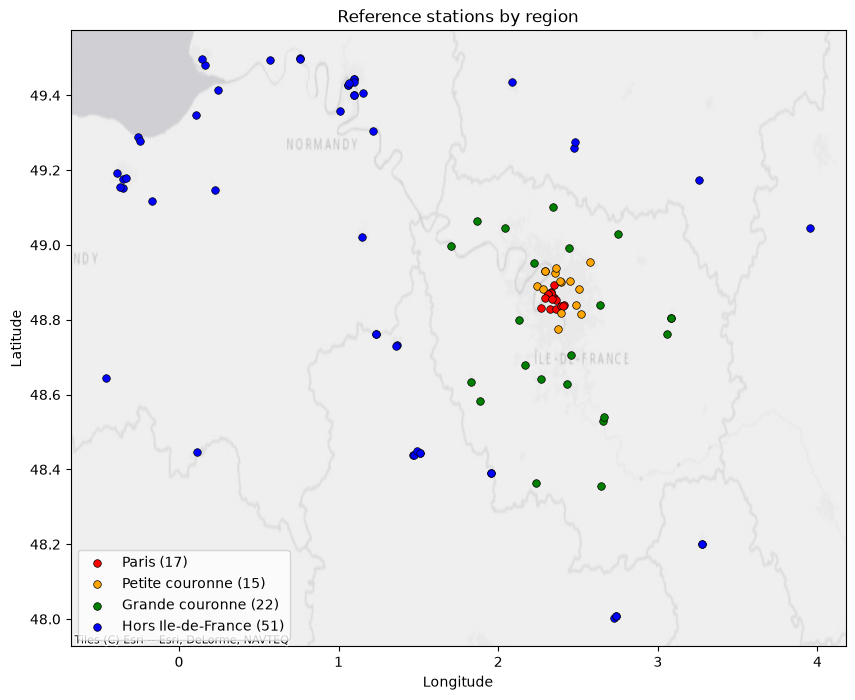

In [9]:
# Plot the reference stations on a map, colored by region.
 
import matplotlib.pyplot as plt
import contextily as ctx

rows = stations_named.select("longitude", "latitude", "region").collect()
colors = {"Paris": "red", "Petite couronne": "orange", "Grande couronne": "green", "Hors Ile-de-France": "blue"}

fig, ax = plt.subplots(figsize=(10, 8))
for region, color in colors.items():
    points = [r for r in rows if r["region"] == region]
    ax.scatter([r["longitude"] for r in points], [r["latitude"] for r in points],
               c=color, s=30, edgecolors="black", linewidths=0.5, label=f"{region} ({len(points)})", zorder=3)
ctx.add_basemap(ax, crs="EPSG:4326", source=ctx.providers.Esri.WorldGrayCanvas)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Reference stations by region")
ax.legend(loc="lower left")
plt.show()

## S4 Stations: merge identifiers of the same site

In [13]:
# S4: find station-ID pairs that are really the same physical site (within 600m, active during non-overlapping periods -- i.e. a sensor swap/renumbering) and merge them under one site_id.
 
measured_days = openaq.filter(F.col("parameter").isin(POLLUTANTS)) \
    .select("location_id", "parameter", F.to_date("datetime_utc").alias("day")).distinct()
periods = openaq.filter(F.col("parameter").isin(POLLUTANTS)).groupBy("location_id") \
    .agg(F.to_date(F.min("datetime_utc")).alias("first_day"), F.to_date(F.max("datetime_utc")).alias("last_day"))

a = stations_named.select(F.col("location_id").alias("id_a"), F.col("station").alias("station_a"),
                          F.col("latitude").alias("lat_a"), F.col("longitude").alias("lon_a"))
b = stations_named.select(F.col("location_id").alias("id_b"), F.col("station").alias("station_b"),
                          F.col("latitude").alias("lat_b"), F.col("longitude").alias("lon_b"))
h = F.pow(F.sin(F.radians(F.col("lat_b") - F.col("lat_a")) / 2), 2) \
    + F.cos(F.radians(F.col("lat_a"))) * F.cos(F.radians(F.col("lat_b"))) \
    * F.pow(F.sin(F.radians(F.col("lon_b") - F.col("lon_a")) / 2), 2)

pairs = a.crossJoin(b).filter(F.col("id_a") < F.col("id_b")) \
    .withColumn("distance_m", F.round(2 * 6371000 * F.asin(F.sqrt(h)), 0)) \
    .filter(F.col("distance_m") < 1000)

days_a = measured_days.select(F.col("location_id").alias("id_a"), "parameter", "day")
days_b = measured_days.select(F.col("location_id").alias("id_b"), "parameter", "day")
overlap = pairs.select("id_a", "id_b").join(days_a, "id_a").join(days_b, ["id_b", "parameter", "day"]) \
    .groupBy("id_a", "id_b").agg(F.countDistinct("day").alias("overlap_days"))

pairs = pairs.join(overlap, ["id_a", "id_b"], "left").fillna(0, ["overlap_days"]) \
    .join(periods.select(F.col("location_id").alias("id_a"), F.col("first_day").alias("first_a"),
                         F.col("last_day").alias("last_a")), "id_a") \
    .join(periods.select(F.col("location_id").alias("id_b"), F.col("first_day").alias("first_b"),
                         F.col("last_day").alias("last_b")), "id_b") \
    .withColumn("same_site", (F.col("distance_m") < MAX_DISTANCE_M) & (F.col("overlap_days") <= MAX_OVERLAP_DAYS))

print("Station pairs closer than 1 km:")
pairs.select("id_a", "station_a", "id_b", "station_b", "distance_m", "overlap_days",
             "first_a", "last_a", "first_b", "last_b", "same_site") \
    .orderBy("distance_m").show(50, truncate=False)

links = pairs.filter(F.col("same_site")).select("id_a", "id_b")
neighbours = links.select(F.col("id_b").alias("location_id"), F.col("id_a").alias("neighbour")) \
    .union(links.select(F.col("id_a").alias("location_id"), F.col("id_b").alias("neighbour"))) \
    .groupBy("location_id").agg(F.min("neighbour").alias("min_neighbour"))

stations_site = stations_named.join(neighbours, "location_id", "left") \
    .withColumn("site_id", F.least(F.col("location_id"), F.coalesce(F.col("min_neighbour"), F.col("location_id")))) \
    .drop("min_neighbour")

site_a = stations_site.select(F.col("location_id").alias("id_a"), F.col("site_id").alias("site_a"))
site_b = stations_site.select(F.col("location_id").alias("id_b"), F.col("site_id").alias("site_b"))
print("Linked stations with a different site_id:",
      links.join(site_a, "id_a").join(site_b, "id_b").filter(F.col("site_a") != F.col("site_b")).count())

groups = stations_site.groupBy("site_id").count().filter(F.col("count") > 1).select("site_id")
print("Sites with several identifiers:")
stations_site.join(groups, "site_id").join(periods, "location_id") \
    .select("site_id", "location_id", "station", "first_day", "last_day") \
    .orderBy("site_id", "first_day").show(50, truncate=False)

modified = stations_site.filter(F.col("site_id") != F.col("location_id")).count()
print("Stations:", stations_site.count(), "Sites:", stations_site.select("site_id").distinct().count())
log_rule("stations", "S4 Site identifier", stations_named.count(), stations_site.count(), modified,
         f"Same place (< {MAX_DISTANCE_M} m) and successive periods (<= {MAX_OVERLAP_DAYS} days overlap)")

Station pairs closer than 1 km:
+-------+-------------------------+-------+-------------------------+----------+------------+----------+----------+----------+----------+---------+
|id_a   |station_a                |id_b   |station_b                |distance_m|overlap_days|first_a   |last_a    |first_b   |last_b    |same_site|
+-------+-------------------------+-------+-------------------------+----------+------------+----------+----------+----------+----------+---------+
|2162641|Montargis_trafic         |2493596|NET-FR061A               |8.0       |3           |2024-01-28|2026-10-12|2024-02-28|2024-03-04|true     |
|3999   |Saint-Remy               |5686   |FR34047                  |10.0      |1           |2018-04-25|2026-10-12|2018-01-05|2018-04-25|true     |
|3943   |NET-FR069A               |2162687|Rouen Justice            |13.0      |5           |2018-01-05|2024-03-04|2024-01-28|2026-09-18|true     |
|4128   |NET-FR069A               |2162686|Centre Hospitalier       |16.0      |

## O1 OpenAQ: reference stations and target pollutants

In [14]:
# O1: keep only rows from our reference stations, and only our 4 target pollutants (PM2.5, PM10, NO2, O3).
 
openaq_ref_stations = openaq.join(stations_site.select("location_id"), "location_id", "left_semi")
openaq_ref = openaq_ref_stations.filter(F.col("parameter").isin(POLLUTANTS))

before = openaq.count()
after_stations = openaq_ref_stations.count()
after = openaq_ref.count()
print("Rows of low-cost sensors and removed stations:", before - after_stations)
print("Rows of other parameters:", after_stations - after)
openaq_ref.groupBy("parameter", "units").count().orderBy("parameter").show()

openaq_ref = openaq_ref.select("location_id", "sensors_id", "parameter", "value", "datetime_utc", "lat", "lon").cache()
log_rule("openaq", "O1 Reference stations and target pollutants", before, after, 0,
         "Sub-question uses PM2.5, PM10, NO2 and O3 of reference stations")

Rows of low-cost sensors and removed stations: 668353
Rows of other parameters: 873797
+---------+-----+-------+
|parameter|units|  count|
+---------+-----+-------+
|      no2|µg/m³|3079616|
|       o3|µg/m³|2234750|
|     pm10|µg/m³|1997370|
|     pm25|µg/m³|1261843|
+---------+-----+-------+

O1 Reference stations and target pollutants: before = 10115729, removed = 1542150, modified = 0, after = 8573579


## O2 OpenAQ: truncate timestamps to the hour

In [15]:
# O2: round every timestamp down to the start of its hour, since weather is an hourly grid and we need whole hours to join on.
 
openaq_hour = openaq_ref.withColumn("datetime_hour", F.date_trunc("hour", F.col("datetime_utc")))

not_on_hour = openaq_hour.filter(F.col("datetime_hour") != F.col("datetime_utc"))
not_on_hour.groupBy("location_id", "parameter").count().orderBy("location_id", "parameter").show()
modified = not_on_hour.count()

openaq_hour = openaq_hour.drop("datetime_utc").withColumnRenamed("datetime_hour", "datetime_utc")
log_rule("openaq", "O2 Hour truncation", openaq_ref.count(), openaq_hour.count(), modified,
         "Hourly join with weather needs whole hours")

+-----------+---------+-----+
|location_id|parameter|count|
+-----------+---------+-----+
+-----------+---------+-----+

O2 Hour truncation: before = 8573579, removed = 0, modified = 0, after = 8573579


## O3 OpenAQ: period and coordinates

In [16]:
# O3: keep only rows between 2018-01-01 and the actual download time (catches corrupted future timestamps), and only coordinates inside mainland France.
 
ingestion_time = datetime.fromtimestamp(os.path.getmtime(PROCESSED + "/openaq/_SUCCESS"), timezone.utc)
ingestion_str = ingestion_time.strftime("%Y-%m-%d %H:%M:%S")
print("Ingestion time (UTC):", ingestion_str)

in_period = F.col("datetime_utc").between("2018-01-01 00:00:00", ingestion_str)
in_france = F.col("lat").between(41, 51.5) & F.col("lon").between(-5.5, 10)

before = openaq_hour.count()
print("Rows outside the period:", openaq_hour.filter(~in_period | F.col("datetime_utc").isNull()).count())
print("Rows outside metropolitan France:",
      openaq_hour.filter(~in_france | F.col("lat").isNull() | F.col("lon").isNull()).count())

openaq_period = openaq_hour.filter(in_period & in_france).drop("lat", "lon")
log_rule("openaq", "O3 Period and coordinates", before, openaq_period.count(), 0,
         "Timestamps between 2018-01-01 and ingestion, coordinates in France")

Ingestion time (UTC): 2026-10-17 16:20:33
Rows outside the period: 0
Rows outside metropolitan France: 0
O3 Period and coordinates: before = 8573579, removed = 0, modified = 0, after = 8573579


## Distribution of the values before removing outliers


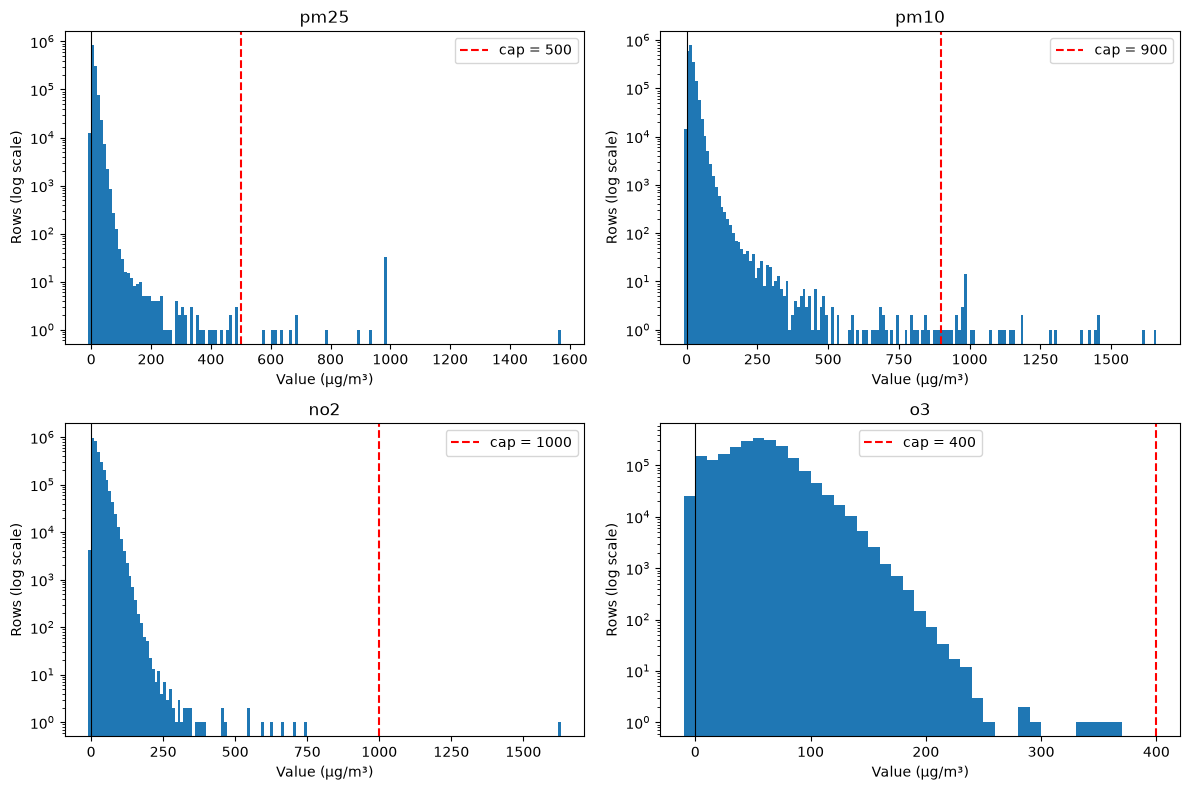

In [18]:
# Plot the value distribution per pollutant (log scale) before deciding on an outlier cap, with the proposed cap marked on the chart.
 
import matplotlib.pyplot as plt

bins = openaq_period.withColumn("bin", (F.floor(F.col("value") / 10) * 10).cast("int")) \
    .groupBy("parameter", "bin").count().collect()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, p in zip(axes.flatten(), POLLUTANTS):
    data = sorted((r["bin"], r["count"]) for r in bins if r["parameter"] == p)
    ax.bar([b for b, c in data], [c for b, c in data], width=10, align="edge")
    ax.set_yscale("log")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.axvline(CAPS[p], color="red", linestyle="--", label=f"cap = {CAPS[p]}")
    ax.set_title(p)
    ax.set_xlabel("Value (µg/m³)")
    ax.set_ylabel("Rows (log scale)")
    ax.legend()
plt.tight_layout()
plt.show()

## O4 OpenAQ: missing and negative values

In [17]:
# O4: drop rows with a missing or negative value -- a concentration can't be negative, and we never invent a replacement.
 
before = openaq_period.count()
print("Missing values:", openaq_period.filter(F.col("value").isNull()).count())
openaq_period.filter(F.col("value") < 0).groupBy("parameter") \
    .agg(F.count("*").alias("negative_rows"), F.min("value").alias("min_value")).orderBy("parameter").show()

openaq_positive = openaq_period.filter(F.col("value").isNotNull() & (F.col("value") >= 0))
log_rule("openaq", "O4 Missing and negative values", before, openaq_positive.count(), 0,
         "A concentration cannot be negative, no value is imputed")

Missing values: 0
+---------+-------------+---------+
|parameter|negative_rows|min_value|
+---------+-------------+---------+
|      no2|         4289|     -3.3|
|       o3|        25663|     -3.4|
|     pm10|        14380|     -3.0|
|     pm25|        12427|     -3.0|
+---------+-------------+---------+

O4 Missing and negative values: before = 8573579, removed = 56759, modified = 0, after = 8516820


## O5 OpenAQ: physical caps

In [19]:
# O5: look at the 99th/99.9th/99.99th percentile per pollutant (and check for the suspicious exact value 985, a likely sensor error code), then drop anything above a fixed physical cap.
 
openaq_positive.createOrReplaceTempView("openaq_positive")
spark.sql("""
    SELECT parameter,
           percentile_approx(value, 0.99, 100000) AS p99,
           percentile_approx(value, 0.999, 100000) AS p99_9,
           percentile_approx(value, 0.9999, 100000) AS p99_99,
           MAX(value) AS max_value,
           SUM(CASE WHEN value = 985 THEN 1 ELSE 0 END) AS values_985
    FROM openaq_positive
    GROUP BY parameter
    ORDER BY parameter
""").show()

caps = spark.createDataFrame(list(CAPS.items()), ["parameter", "cap"])
openaq_with_cap = openaq_positive.join(F.broadcast(caps), "parameter")
openaq_with_cap.filter(F.col("value") > F.col("cap")).groupBy("parameter", "cap") \
    .agg(F.count("*").alias("removed_rows"), F.max("value").alias("max_value")).orderBy("parameter").show()

openaq_capped = openaq_with_cap.filter(F.col("value") <= F.col("cap")).drop("cap")
log_rule("openaq", "O5 Physical caps", openaq_positive.count(), openaq_capped.count(), 0,
         "Values far above the 99.99th percentile and saturation code 985")

+---------+-----+-----+------+---------+----------+
|parameter|  p99|p99_9|p99_99|max_value|values_985|
+---------+-----+-----+------+---------+----------+
|      no2| 89.2|128.3| 171.4|   1625.7|         0|
|       o3|129.1|162.3| 193.4|    363.1|         0|
|     pm10|62.23|114.4| 286.8|   1654.7|        13|
|     pm25| 38.8| 62.1| 145.7|   1560.1|        30|
+---------+-----+-----+------+---------+----------+

+---------+----+------------+---------+
|parameter| cap|removed_rows|max_value|
+---------+----+------------+---------+
|      no2|1000|           1|   1625.7|
|     pm10| 900|          43|   1654.7|
|     pm25| 500|          43|   1560.1|
+---------+----+------------+---------+

O5 Physical caps: before = 8516820, removed = 87, modified = 0, after = 8516733


## O6 OpenAQ: stuck sensors

In [20]:
# O6: find sensors stuck on the exact same reading for 24+ consecutive hours (a frozen sensor, not real data) and drop those runs.
 
w = Window.partitionBy("sensors_id").orderBy("datetime_utc", "value")
openaq_runs = openaq_capped \
    .withColumn("prev_value", F.lag("value").over(w)) \
    .withColumn("prev_time", F.lag("datetime_utc").over(w)) \
    .withColumn("gap_hours", (F.col("datetime_utc").cast("long") - F.col("prev_time").cast("long")) / 3600) \
    .withColumn("new_run", F.when((F.col("value") == F.col("prev_value")) & (F.col("gap_hours") <= 1), 0).otherwise(1)) \
    .withColumn("run_id", F.sum("new_run").over(w.rowsBetween(Window.unboundedPreceding, Window.currentRow)))

runs = openaq_runs.groupBy("sensors_id", "run_id") \
    .agg(F.first("location_id").alias("location_id"), F.first("parameter").alias("parameter"),
         F.first("value").alias("value"), F.min("datetime_utc").alias("start"),
         F.max("datetime_utc").alias("end"), F.count("*").alias("rows")) \
    .withColumn("duration_hours", ((F.col("end").cast("long") - F.col("start").cast("long")) / 3600 + 1).cast("int"))
stuck_runs = runs.filter(F.col("duration_hours") >= STUCK_HOURS).cache()

print("Stuck series:", stuck_runs.count())
stuck_runs.groupBy("parameter").agg(F.count("*").alias("series"), F.sum("rows").alias("rows")).orderBy("parameter").show()
stuck_runs.join(stations_site.select("location_id", "station"), "location_id") \
    .select("location_id", "station", "parameter", "value", "duration_hours", "start") \
    .orderBy(F.desc("duration_hours")).show(50, truncate=False)

openaq_unstuck = openaq_runs.join(stuck_runs.select("sensors_id", "run_id"), ["sensors_id", "run_id"], "left_anti") \
    .select("location_id", "sensors_id", "parameter", "value", "datetime_utc").cache()
log_rule("openaq", "O6 Stuck sensors", openaq_capped.count(), openaq_unstuck.count(), 0,
         f"Same value during at least {STUCK_HOURS} consecutive hours")

Stuck series: 5
+---------+------+----+
|parameter|series|rows|
+---------+------+----+
|      no2|     1|  69|
|       o3|     1|  32|
|     pm10|     2|  66|
|     pm25|     1|  69|
+---------+------+----+

+-----------+-------------------+---------+-----+--------------+-------------------+
|location_id|station            |parameter|value|duration_hours|start              |
+-----------+-------------------+---------+-----+--------------+-------------------+
|3618       |Faiencerie Creil   |pm25     |17.8 |69            |2023-06-09 09:00:00|
|3618       |Faiencerie Creil   |no2      |19.7 |69            |2023-06-09 09:00:00|
|3461       |Gd Couronne Mairie |pm10     |0.0  |36            |2023-04-23 01:00:00|
|4123       |CHAMPIGNY-SUR-MARNE|o3       |0.0  |32            |2018-11-26 03:00:00|
|2681       |Place de l'Opéra   |pm10     |0.0  |30            |2019-07-01 01:00:00|
+-----------+-------------------+---------+-----+--------------+-------------------+

O6 Stuck sensors: before 

## O7 OpenAQ: one row per station, pollutant and hour

In [21]:
# O7: after rounding to the hour, a sensor can have more than one reading in the same hour -- average them into a single value per station/pollutant/hour.
 
openaq_hourly = openaq_unstuck.groupBy("location_id", "parameter", "datetime_utc") \
    .agg(F.avg("value").alias("value"), F.count("*").alias("merged_rows"))

merged = openaq_hourly.filter(F.col("merged_rows") > 1)
merged.groupBy("location_id", "parameter") \
    .agg(F.count("*").alias("hours"), F.sum("merged_rows").alias("rows")).orderBy("location_id", "parameter").show()

log_rule("openaq", "O7 One row per station, pollutant and hour", openaq_unstuck.count(), openaq_hourly.count(),
         merged.count(), "Several values in the same hour are averaged")

+-----------+---------+-----+----+
|location_id|parameter|hours|rows|
+-----------+---------+-----+----+
+-----------+---------+-----+----+

O7 One row per station, pollutant and hour: before = 8516497, removed = 0, modified = 0, after = 8516497


## OpenAQ: add site and region, write openaq_clean

In [22]:
# Attach site_id and region, add a year column, and write the final cleaned OpenAQ table, partitioned by year.
 
openaq_clean = openaq_hourly.drop("merged_rows") \
    .join(stations_site.select("location_id", "site_id", "department", "region"), "location_id") \
    .withColumn("year", F.year("datetime_utc"))

print("Rows with the same site, pollutant and hour:",
      openaq_clean.groupBy("site_id", "parameter", "datetime_utc").count().filter(F.col("count") > 1).count())

openaq_clean.repartition("year").write.mode("overwrite").partitionBy("year").parquet(PROCESSED + "/openaq_clean")

openaq_clean = spark.read.parquet(PROCESSED + "/openaq_clean")
openaq_clean.printSchema()
print("Rows:", openaq_clean.count())
print("Stations:", openaq_clean.select("location_id").distinct().count(),
      "Sites:", openaq_clean.select("site_id").distinct().count())
openaq_clean.groupBy("region").pivot("parameter", POLLUTANTS).count().orderBy("region").show()
openaq_clean.groupBy("year").count().orderBy("year").show()

Rows with the same site, pollutant and hour: 625
root
 |-- location_id: integer (nullable = true)
 |-- parameter: string (nullable = true)
 |-- datetime_utc: timestamp (nullable = true)
 |-- value: double (nullable = true)
 |-- site_id: integer (nullable = true)
 |-- department: string (nullable = true)
 |-- region: string (nullable = true)
 |-- year: integer (nullable = true)

Rows: 8516497
Stations: 105 Sites: 89
+------------------+------+------+-------+------+
|            region|  pm25|  pm10|    no2|    o3|
+------------------+------+------+-------+------+
|   Grande couronne|329014|356131| 674193|837517|
|Hors Ile-de-France|581095|984108|1045748|950406|
|             Paris|117814|289757| 695076|140778|
|   Petite couronne|221381|352885| 660240|280354|
+------------------+------+------+-------+------+

+----+-------+
|year|  count|
+----+-------+
|2018|1061829|
|2019|1241114|
|2020|1183587|
|2021| 482467|
|2022| 564652|
|2023|1044421|
|2024| 884943|
|2025|1091678|
|2026| 961806|


## Overview of openaq_clean

+-----------+---------+-------------------+-----+-------+----------+------------------+----+
|location_id|parameter|       datetime_utc|value|site_id|department|            region|year|
+-----------+---------+-------------------+-----+-------+----------+------------------+----+
|       4092|     pm25|2018-01-05 01:00:00|  6.6|   4092|        91|   Grande couronne|2018|
|       3666|     pm10|2018-01-05 01:00:00|16.13|   3666|        60|Hors Ile-de-France|2018|
|       4126|       o3|2018-01-05 01:00:00|87.73|   4126|        76|Hors Ile-de-France|2018|
|       4088|      no2|2018-01-05 01:00:00| 6.75|   4088|        92|   Petite couronne|2018|
|       4153|       o3|2018-01-05 01:00:00|68.75|   4153|        92|   Petite couronne|2018|
+-----------+---------+-------------------+-----+-------+----------+------------------+----+
only showing top 5 rows

+---------+-------+-----+---+----+-----+
|parameter|   rows|sites|min|mean|  max|
+---------+-------+-----+---+----+-----+
|      no2|3075

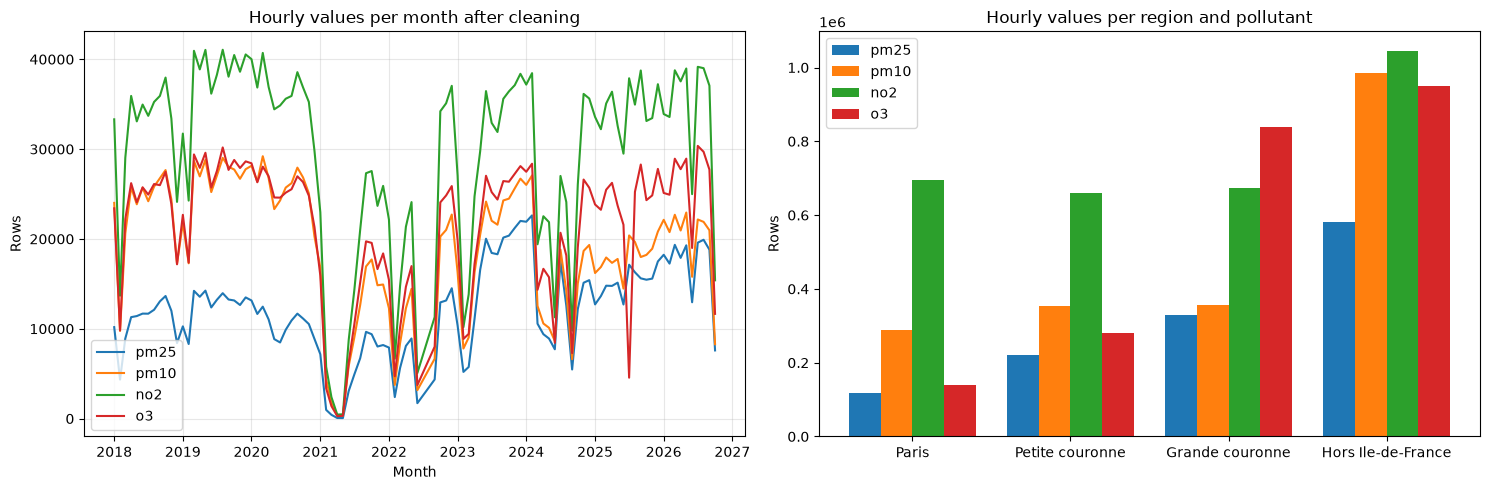

In [23]:
# Sanity check the saved table: sample rows, per-pollutant stats, and counts by region and year.
 
openaq_clean.orderBy("datetime_utc").show(5)
openaq_clean.groupBy("parameter").agg(
    F.count("*").alias("rows"),
    F.countDistinct("site_id").alias("sites"),
    F.round(F.min("value"), 1).alias("min"),
    F.round(F.avg("value"), 1).alias("mean"),
    F.round(F.max("value"), 1).alias("max")
).orderBy("parameter").show()

monthly = openaq_clean.groupBy(F.date_trunc("month", "datetime_utc").alias("month"), "parameter") \
    .count().orderBy("month").collect()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for p in POLLUTANTS:
    points = [r for r in monthly if r["parameter"] == p]
    axes[0].plot([r["month"] for r in points], [r["count"] for r in points], label=p)
axes[0].set_title("Hourly values per month after cleaning")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Rows")
axes[0].legend()
axes[0].grid(alpha=0.3)

region_counts = openaq_clean.groupBy("region", "parameter").count().collect()
regions = ["Paris", "Petite couronne", "Grande couronne", "Hors Ile-de-France"]
width = 0.2
for i, p in enumerate(POLLUTANTS):
    values = [next((r["count"] for r in region_counts if r["region"] == reg and r["parameter"] == p), 0) for reg in regions]
    axes[1].bar([x + i * width for x in range(len(regions))], values, width, label=p)
axes[1].set_xticks([x + 1.5 * width for x in range(len(regions))])
axes[1].set_xticklabels(regions)
axes[1].set_title("Hourly values per region and pollutant")
axes[1].set_ylabel("Rows")
axes[1].legend()

plt.tight_layout()
plt.show()

## W1 Weather: reference stations

In [30]:
# W1: keep only weather rows for the same reference stations we kept for OpenAQ.
 
weather_ref = weather.join(stations_site.select("location_id"), "location_id", "left_semi")
print("Weather stations kept:", weather_ref.select("location_id").distinct().count())
log_rule("weather", "W1 Reference stations", weather.count(), weather_ref.count(), 0,
         "Same stations as the clean OpenAQ table")

Weather stations kept: 105
W1 Reference stations: before = 10384200, removed = 2307600, modified = 0, after = 8076600


## W2 Weather: physical ranges

In [31]:
# W2: drop rows with a physically impossible reading -- temperature outside -30 to 45C, humidity outside 0-100%, or negative rain/wind.
 
weather_ref.agg(
    F.min("temperature_2m"), F.max("temperature_2m"),
    F.min("relative_humidity_2m"), F.max("relative_humidity_2m"),
    F.min("precipitation"), F.max("precipitation"),
    F.min("wind_speed_10m"), F.max("wind_speed_10m")
).show()

valid_temperature = F.col("temperature_2m").between(-30, 45)
valid_humidity = F.col("relative_humidity_2m").between(0, 100)
valid_precipitation = F.col("precipitation") >= 0
valid_wind = F.col("wind_speed_10m") >= 0

weather_ref.select(
    F.sum(F.when(valid_temperature, 0).otherwise(1)).alias("bad_temperature"),
    F.sum(F.when(valid_humidity, 0).otherwise(1)).alias("bad_humidity"),
    F.sum(F.when(valid_precipitation, 0).otherwise(1)).alias("bad_precipitation"),
    F.sum(F.when(valid_wind, 0).otherwise(1)).alias("bad_wind")
).show()

weather_ranges = weather_ref.filter(valid_temperature & valid_humidity & valid_precipitation & valid_wind)
log_rule("weather", "W2 Physical ranges", weather_ref.count(), weather_ranges.count(), 0,
         "Temperature -30 to 45, humidity 0 to 100, rain and wind >= 0, no missing value")

+-------------------+-------------------+-------------------------+-------------------------+------------------+------------------+-------------------+-------------------+
|min(temperature_2m)|max(temperature_2m)|min(relative_humidity_2m)|max(relative_humidity_2m)|min(precipitation)|max(precipitation)|min(wind_speed_10m)|max(wind_speed_10m)|
+-------------------+-------------------+-------------------------+-------------------------+------------------+------------------+-------------------+-------------------+
|              -12.0|               42.5|                      9.0|                    100.0|               0.0|              17.3|                0.0|               66.1|
+-------------------+-------------------+-------------------------+-------------------------+------------------+------------------+-------------------+-------------------+

+---------------+------------+-----------------+--------+
|bad_temperature|bad_humidity|bad_precipitation|bad_wind|
+---------------+------

## W3 Weather: wind speed in m/s

In [33]:
# W3: convert wind speed from km/h to m/s (the SI unit).
 
weather_ms = weather_ranges.withColumn("wind_speed_ms", F.round(F.col("wind_speed_10m") / 3.6, 2)).drop("wind_speed_10m")
weather_ms.select(F.min("wind_speed_ms"), F.avg("wind_speed_ms"), F.max("wind_speed_ms")).show()
rows = weather_ms.count()
log_rule("weather", "W3 Wind speed in m/s", weather_ranges.count(), rows, rows, "SI unit: km/h divided by 3.6")

+------------------+------------------+------------------+
|min(wind_speed_ms)|avg(wind_speed_ms)|max(wind_speed_ms)|
+------------------+------------------+------------------+
|               0.0|3.7272812383919995|             18.36|
+------------------+------------------+------------------+

W3 Wind speed in m/s: before = 8076600, removed = 0, modified = 8076600, after = 8076600


## W4 Weather: duplicates and missing hours

In [34]:
# W4: check for duplicate (station, hour) rows and for stations with gaps in their hourly series. Check only -- nothing is dropped here.
 
rows = weather_ms.count()
print("Duplicated (location_id, datetime_utc):", rows - weather_ms.select("location_id", "datetime_utc").distinct().count())

hours_per_station = weather_ms.groupBy("location_id") \
    .agg(F.count("*").alias("rows"), F.min("datetime_utc").alias("first_hour"), F.max("datetime_utc").alias("last_hour")) \
    .withColumn("expected_rows", ((F.col("last_hour").cast("long") - F.col("first_hour").cast("long")) / 3600 + 1).cast("long")) \
    .withColumn("missing_hours", F.col("expected_rows") - F.col("rows"))
print("Stations with missing hours:", hours_per_station.filter(F.col("missing_hours") != 0).count())
hours_per_station.orderBy(F.desc("missing_hours"), "location_id").show(5)

log_rule("weather", "W4 Duplicates and missing hours", rows, rows, 0, "Check only: complete hourly series")

Duplicated (location_id, datetime_utc): 0
Stations with missing hours: 0
+-----------+-----+-------------------+-------------------+-------------+-------------+
|location_id| rows|         first_hour|          last_hour|expected_rows|missing_hours|
+-----------+-----+-------------------+-------------------+-------------+-------------+
|       2681|76920|2018-01-01 00:00:00|2026-10-10 23:00:00|        76920|            0|
|       2707|76920|2018-01-01 00:00:00|2026-10-10 23:00:00|        76920|            0|
|       2708|76920|2018-01-01 00:00:00|2026-10-10 23:00:00|        76920|            0|
|       3461|76920|2018-01-01 00:00:00|2026-10-10 23:00:00|        76920|            0|
|       3496|76920|2018-01-01 00:00:00|2026-10-10 23:00:00|        76920|            0|
+-----------+-----+-------------------+-------------------+-------------+-------------+
only showing top 5 rows

W4 Duplicates and missing hours: before = 8076600, removed = 0, modified = 0, after = 8076600


## Weather: write weather_clean

In [35]:
# Select the final columns and write the cleaned weather table, partitioned by year.
 
weather_clean = weather_ms.select("location_id", "datetime_utc", "temperature_2m", "relative_humidity_2m",
                                  "precipitation", "wind_speed_ms", "year")
weather_clean.repartition("year").write.mode("overwrite").partitionBy("year").parquet(PROCESSED + "/weather_clean")

weather_clean = spark.read.parquet(PROCESSED + "/weather_clean")
weather_clean.printSchema()
print("Rows:", weather_clean.count())
weather_clean.show(5)

root
 |-- location_id: integer (nullable = true)
 |-- datetime_utc: timestamp (nullable = true)
 |-- temperature_2m: double (nullable = true)
 |-- relative_humidity_2m: double (nullable = true)
 |-- precipitation: double (nullable = true)
 |-- wind_speed_ms: double (nullable = true)
 |-- year: integer (nullable = true)

Rows: 8076600
+-----------+-------------------+--------------+--------------------+-------------+-------------+----+
|location_id|       datetime_utc|temperature_2m|relative_humidity_2m|precipitation|wind_speed_ms|year|
+-----------+-------------------+--------------+--------------------+-------------+-------------+----+
|    4234128|2024-01-01 00:00:00|           7.6|                79.0|          0.3|         8.28|2024|
|    4234128|2024-01-01 01:00:00|           7.5|                79.0|          0.1|         8.06|2024|
|    4234128|2024-01-01 02:00:00|           7.3|                82.0|          0.3|         7.78|2024|
|    4234128|2024-01-01 03:00:00|           7.

## Stations: write stations_clean

In [36]:
# Write the final cleaned station reference table (one row per site).
 
stations_clean = stations_site.select("location_id", "site_id", "station", "locality", "commune", "insee_code",
                                      "department", "region", "latitude", "longitude", "pollutants")
stations_clean.coalesce(1).write.mode("overwrite").parquet(PROCESSED + "/stations_clean")

stations_clean = spark.read.parquet(PROCESSED + "/stations_clean")
print("Stations:", stations_clean.count(), "Sites:", stations_clean.select("site_id").distinct().count())
stations_clean.orderBy("region", "location_id").show(5, truncate=False)

Stations: 105 Sites: 89
+-----------+-------+--------------------+---------------+---------------+----------+----------+---------------+------------------+------------------+-------------------+
|location_id|site_id|station             |locality       |commune        |insee_code|department|region         |latitude          |longitude         |pollutants         |
+-----------+-------+--------------------+---------------+---------------+----------+----------+---------------+------------------+------------------+-------------------+
|3916       |3916   |Zone Rurale Nord-Est|MONTGÉ-EN-GOËLE|Montgé-en-Goële|77308     |77        |Grande couronne|49.02805700016036 |2.7502780000005136|o3                 |
|4043       |4043   |RN6-MELUN           |MELUN          |Melun          |77288     |77        |Grande couronne|48.52805700012826 |2.6536110001488558|no, no2, pm10, pm25|
|4058       |4058   |GONESSE             |GONESSE        |Gonesse        |95277     |95        |Grande couronne|48.990830

## Summary of the cleaning rules

In [37]:
# Build one summary table from every log_rule() call above: rows before/after/removed/modified and why, ready to paste into the report.
 
summary = spark.createDataFrame(list(report.values()),
                                ["table", "rule", "rows_before", "rows_removed", "rows_modified", "rows_after", "reason"])
summary.show(truncate=False)

+--------+-------------------------------------------+-----------+------------+-------------+----------+------------------------------------------------------------------------------+
|table   |rule                                       |rows_before|rows_removed|rows_modified|rows_after|reason                                                                        |
+--------+-------------------------------------------+-----------+------------+-------------+----------+------------------------------------------------------------------------------+
|stations|S1 Reference stations                      |135        |30          |0            |105       |Low-cost sensors and stations without data removed                            |
|stations|S2 Department and region                   |105        |0           |105          |105       |Region from the department of the commune (API Geo)                           |
|stations|S3 Station names                           |105        |0           |1

## Stop Spark

In [38]:
# Shut down the Spark session.
 
spark.stop()